In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats

# --- Generate 500 customer review ratings (1 to 5 stars) ---
np.random.seed(22)
ratings = np.random.choice([1, 2, 3, 4, 5], p=[0.05, 0.10, 0.20, 0.35, 0.30], size=600)
df_reviews = pd.DataFrame({'rating': ratings})
df_reviews.to_csv('customer_reviews.csv', index=False)

# Read dataset
df_rev = pd.read_csv('customer_reviews.csv')

mean_rating = df_rev['rating'].mean()
sem_rating = stats.sem(df_rev['rating'])
ci_rating = stats.t.interval(0.95, df=len(df_rev)-1, loc=mean_rating, scale=sem_rating)

print(f"Total Reviews Analyzed: {len(df_rev)}")
print(f"Mean Rating: {mean_rating:.2f}")
print(f"95% Confidence Interval for True Mean Rating: ({ci_rating[0]:.4f}, {ci_rating[1]:.4f})")


Total Reviews Analyzed: 600
Mean Rating: 3.71
95% Confidence Interval for True Mean Rating: (3.6154, 3.8046)


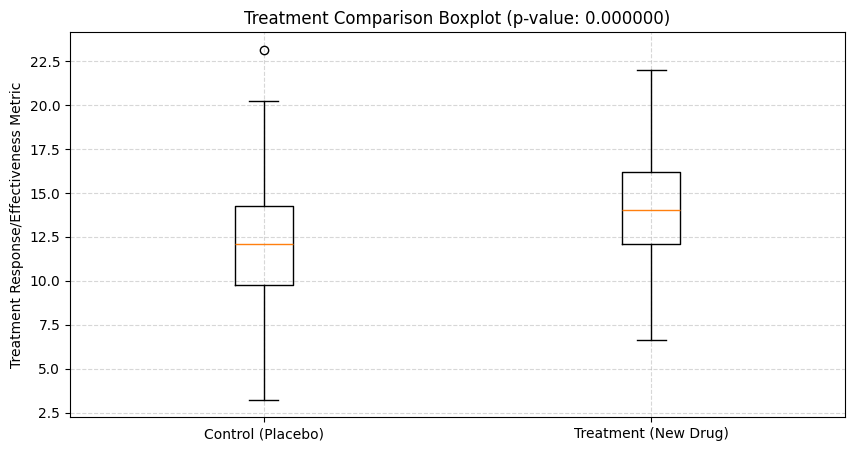

T-Statistic: 7.2646
P-Value: 0.000000
The difference between groups is statistically significant.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# --- Generate dataset ---
np.random.seed(23)
control_group = np.random.normal(loc=12, scale=3.5, size=250)
treatment_group = np.random.normal(loc=14.5, scale=3.2, size=250)

t_stat, p_value = stats.ttest_ind(treatment_group, control_group)

# Plot the results
plt.figure(figsize=(10, 5))
plt.boxplot([control_group, treatment_group], tick_labels=['Control (Placebo)', 'Treatment (New Drug)'])
plt.title(f'Treatment Comparison Boxplot (p-value: {p_value:.6f})')
plt.ylabel('Treatment Response/Effectiveness Metric')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.6f}")
if p_value < 0.05:
    print("The difference between groups is statistically significant.")
else:
    print("The difference is not statistically significant.")


In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# --- Generate 500 patient symptom records ---
np.random.seed(24)
body_temp = np.random.normal(loc=37.5, scale=1.2, size=500)
heart_rate = np.random.normal(loc=80, scale=15, size=500)
labels = ((body_temp > 38) | (heart_rate > 95)).astype(int)

X = pd.DataFrame({'Body_Temp': body_temp, 'Heart_Rate': heart_rate})
y = pd.Series(labels)

# Split and train KNN
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

input_temp = float(input("Enter body temperature (e.g., 38.5): ") or 38.5)
input_hr = float(input("Enter heart rate (e.g., 100): ") or 100.0)

prediction = knn.predict([[input_temp, input_hr]])[0]
print(f"\nPredicted Medical Condition Class: {prediction} ('No Condition' if 0 else 'Has Condition')")


Enter body temperature (e.g., 38.5): 36
Enter heart rate (e.g., 100): 98

Predicted Medical Condition Class: 1 ('No Condition' if 0 else 'Has Condition')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [4]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

# --- Use scikit-learn Iris dataset and map prediction ---
iris = load_iris()
X, y = iris.data, iris.target

# Train Decision Tree
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X, y)

s_length = float(input("Enter sepal length: ") or 5.1)
s_width = float(input("Enter sepal width: ") or 3.5)
p_length = float(input("Enter petal length: ") or 1.4)
p_width = float(input("Enter petal width: ") or 0.2)

pred = clf.predict([[s_length, s_width, p_length, p_width]])[0]
print(f"\nPredicted Species: {iris.target_names[pred]} ({pred})")


Enter sepal length: 6
Enter sepal width: 3
Enter petal length: 5
Enter petal width: 3

Predicted Species: virginica (2)


In [5]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# --- Generate 500 house sales data ---
np.random.seed(26)
area = np.random.randint(800, 4000, size=500)
bedrooms = np.random.randint(1, 6, size=500)
price = area * 150 + bedrooms * 10000 + np.random.normal(0, 15000, size=500)

X = pd.DataFrame({'Area': area, 'Bedrooms': bedrooms})
y = pd.Series(price)

model = LinearRegression()
model.fit(X, y)

in_area = float(input("Enter Area in sqft (e.g., 2000): ") or 2000.0)
in_beds = float(input("Enter number of bedrooms (e.g., 3): ") or 3.0)

predicted_price = model.predict([[in_area, in_beds]])[0]
print(f"\nPredicted Price: ${predicted_price:,.2f}")


Enter Area in sqft (e.g., 2000): 1976
Enter number of bedrooms (e.g., 3): 2

Predicted Price: $315,941.87


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [6]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# --- Generate 500 customer records ---
np.random.seed(27)
usage_minutes = np.random.randint(50, 1000, size=500)
contract_duration = np.random.randint(1, 24, size=500)
churn_prob = 1 / (1 + np.exp(-(0.002 * usage_minutes - 0.1 * contract_duration)))
churn = (np.random.rand(500) < churn_prob).astype(int)

X = pd.DataFrame({'Usage_Minutes': usage_minutes, 'Contract_Duration': contract_duration})
y = pd.Series(churn)

clf = LogisticRegression()
clf.fit(X, y)

in_usage = float(input("Enter Usage Minutes (e.g., 400): ") or 400.0)
in_contract = float(input("Enter Contract Duration in months (e.g., 12): ") or 12.0)

pred_churn = clf.predict([[in_usage, in_contract]])[0]
print(f"\nPredicted Churn Status: {'Churned (1)' if pred_churn == 1 else 'Retained (0)'}")


Enter Usage Minutes (e.g., 400): 555
Enter Contract Duration in months (e.g., 12): 11

Predicted Churn Status: Retained (0)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [7]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# --- Generate 500 transaction records ---
np.random.seed(28)
spend = np.random.uniform(10, 500, size=500)
visits = np.random.randint(1, 30, size=500)
X = pd.DataFrame({'Total_Spend': spend, 'Visits': visits})

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X)

in_spend = float(input("Enter customer Total Spend: ") or 250.0)
in_visits = float(input("Enter customer Visits: ") or 10.0)

segment = kmeans.predict([[in_spend, in_visits]])[0]
print(f"\nAssigned Segment / Cluster: {segment}")


Enter customer Total Spend: 234
Enter customer Visits: 5

Assigned Segment / Cluster: 2


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [8]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# --- Load default dataset with target variable ---
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

# Compute evaluation metrics
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")


Accuracy:  0.9650
Precision: 0.9667
Recall:    0.9775
F1-Score:  0.9721


In [9]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, export_text

# --- Generate 500 car listing records ---
np.random.seed(30)
mileage = np.random.randint(5000, 150000, size=500)
age = np.random.randint(1, 15, size=500)
price = 35000 - age * 1800 - mileage * 0.1 + np.random.normal(0, 2000, size=500)

X = pd.DataFrame({'Mileage': mileage, 'Age': age})
y = pd.Series(price)

reg = DecisionTreeRegressor(max_depth=3, random_state=42)
reg.fit(X, y)

in_mileage = float(input("Enter car Mileage (e.g., 40000): ") or 40000.0)
in_age = float(input("Enter car Age (e.g., 4): ") or 4.0)

pred_val = reg.predict([[in_mileage, in_age]])[0]
print(f"\nPredicted Car Price: ${pred_val:,.2f}")

print("\nDecision Path Structure:")
print(export_text(reg, feature_names=['Mileage', 'Age']))


Enter car Mileage (e.g., 40000): 55333
Enter car Age (e.g., 4): 3

Predicted Car Price: $26,603.19

Decision Path Structure:
|--- Age <= 8.50
|   |--- Mileage <= 58829.50
|   |   |--- Age <= 4.50
|   |   |   |--- value: [26603.19]
|   |   |--- Age >  4.50
|   |   |   |--- value: [19551.86]
|   |--- Mileage >  58829.50
|   |   |--- Age <= 4.50
|   |   |   |--- value: [19185.05]
|   |   |--- Age >  4.50
|   |   |   |--- value: [12350.82]
|--- Age >  8.50
|   |--- Mileage <= 89524.00
|   |   |--- Age <= 11.50
|   |   |   |--- value: [12996.34]
|   |   |--- Age >  11.50
|   |   |   |--- value: [6976.92]
|   |--- Mileage >  89524.00
|   |   |--- Age <= 11.50
|   |   |   |--- value: [4478.59]
|   |   |--- Age >  11.50
|   |   |   |--- value: [-506.26]



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


Cluster centers:
[[53.70283089 49.25112225]
 [78.32366124 75.61212822]
 [60.42104889 17.28314635]
 [50.07578343 83.66848941]]


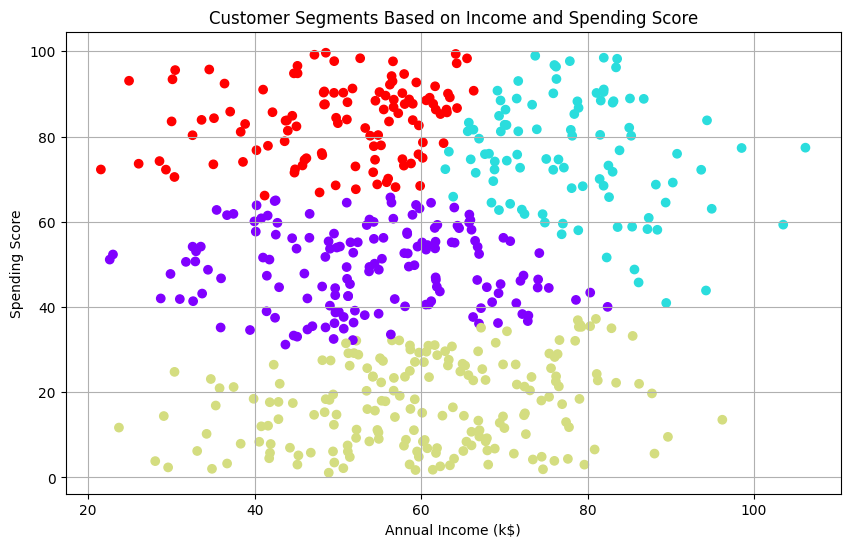

In [10]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# --- Generate 550 records for customer attributes ---
np.random.seed(31)
income = np.random.normal(loc=60, scale=15, size=550) # in thousands
spending_score = np.random.uniform(1, 100, size=550)
df_customers = pd.DataFrame({'Annual_Income': income, 'Spending_Score': spending_score})

kears = KMeans(n_clusters=4, random_state=42, n_init=10)
df_customers['Cluster'] = kears.fit_predict(df_customers)

print("Cluster centers:")
print(kears.cluster_centers_)

# Scatter Plot of segments
plt.figure(figsize=(10, 6))
plt.scatter(df_customers['Annual_Income'], df_customers['Spending_Score'], c=df_customers['Cluster'], cmap='rainbow')
plt.title('Customer Segments Based on Income and Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.grid(True)
plt.show()


In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# --- Generate 500 housing records ---
np.random.seed(32)
house_size = np.random.normal(loc=1800, scale=400, size=500)
price = house_size * 220 + np.random.normal(0, 30000, size=500)
df_homes = pd.DataFrame({'House_Size': house_size, 'Price': price})

X = df_homes[['House_Size']]
y = df_homes['Price']

lr = LinearRegression()
lr.fit(X, y)
preds = lr.predict(X)

print(f"Model Intercept: {lr.intercept_:.2f}")
print(f"Model Coefficient: {lr.coef_[0]:.2f}")
print(f"R2 Score: {r2_score(y, preds):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y, preds)):,.2f}")


Model Intercept: 3025.33
Model Coefficient: 218.79
R2 Score: 0.9050
RMSE: 28,612.95
